# Biomass Hackathon 2026 — Challenge #6

**Pipeline:** Field data → GPKG → CHM update → Allometrics → AGB → Satellite validation

**Site:** Mondah Forest, Gabon

## 1. Data Dictionary

| Column | Description |
|--------|-------------|
| `d_stem` | Stem diameter / DBH (m) |
| `h_t / h_t_mod` | Tree height measured / modeled (m) |
| `wsg` | Wood specific gravity (g/cm³) |
| `m_agb` | AGB per tree (kg) via Chave 2014 |
| `agbd_ha` | Plot-level AGB density (t/ha) |

## 2. Convert Trees CSV → GeoPackage

In [1]:
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point

df = pd.read_csv("Mondah_Field_Data_Trees.csv", encoding="latin-1")
df["x"] = pd.to_numeric(df["x"], errors="coerce")
df["y"] = pd.to_numeric(df["y"], errors="coerce")
df = df.dropna(subset=["x", "y"])

geometry = [Point(xy) for xy in zip(df["x"], df["y"])]
gdf = gpd.GeoDataFrame(df, geometry=geometry, crs="EPSG:32632")
gdf = gdf.drop(columns=["x", "y", "epsg"])
gdf.to_file("Mondah_Trees.gpkg", driver="GPKG", layer="trees")
print(f"Exported {len(gdf)} trees")


Exported 6692 trees


## 3. Convert Plot CSVs → GeoPackage (perfect squares covering all trees)

In [2]:
import pandas as pd
import geopandas as gpd
from shapely import wkt
from shapely.geometry import box
import numpy as np

trees = gpd.read_file("../../../biomass-hackathon-2026/topics/06A-CARBON/Mondah_Trees_updated.gpkg")

def plot_csv_to_gpkg(csv_path, output_path, layer_name, side_m):
    df = pd.read_csv(csv_path, encoding="latin-1")
    df["geometry"] = df["p_geom"].apply(wkt.loads)
    gdf = gpd.GeoDataFrame(df, geometry="geometry", crs="EPSG:32632")
    gdf = gdf.drop(columns=["p_geom", "p_epsg"])
    plot_col = [c for c in gdf.columns if "plot" in c.lower() or "name" in c.lower()][0]

    new_geoms = []
    for idx, row in gdf.iterrows():
        plot_name = row[plot_col]
        plot_trees = trees[trees["plot"] == plot_name]
        if len(plot_trees) > 0:
            minx, miny, maxx, maxy = plot_trees.total_bounds
            cx, cy = (minx + maxx) / 2, (miny + maxy) / 2
            half = max(side_m / 2, (maxx - minx) / 2 + 1, (maxy - miny) / 2 + 1)
            new_geoms.append(box(cx - half, cy - half, cx + half, cy + half))
        else:
            c = row.geometry.centroid
            half = side_m / 2
            new_geoms.append(box(c.x - half, c.y - half, c.x + half, c.y + half))
    gdf["geometry"] = new_geoms
    gdf.to_file(output_path, driver="GPKG", layer=layer_name)
    print(f"Exported {len(gdf)} plots as {side_m}m squares to {output_path}")

plot_csv_to_gpkg("Mondah_Field_Data_Plot-0_0625ha.csv", "Mondah_Plot_0_0625ha.gpkg", "subplots_25m", 25)
plot_csv_to_gpkg("Mondah_Field_Data_Plot-0_25ha.csv",   "Mondah_Plot_0_25ha.gpkg",   "subplots_50m", 50)
plot_csv_to_gpkg("Mondah_Field_Data_Plot-1ha.csv",      "Mondah_Plot_1ha.gpkg",       "subplots_100m", 100)


Exported 240 plots as 25m squares to Mondah_Plot_0_0625ha.gpkg
Exported 60 plots as 50m squares to Mondah_Plot_0_25ha.gpkg
Exported 15 plots as 100m squares to Mondah_Plot_1ha.gpkg


## 4. Visualize AGBD Raster

CRS: EPSG:4326, Size: 27103x16237, Res: (0.0017980138121629352, 0.0018087108088100656)


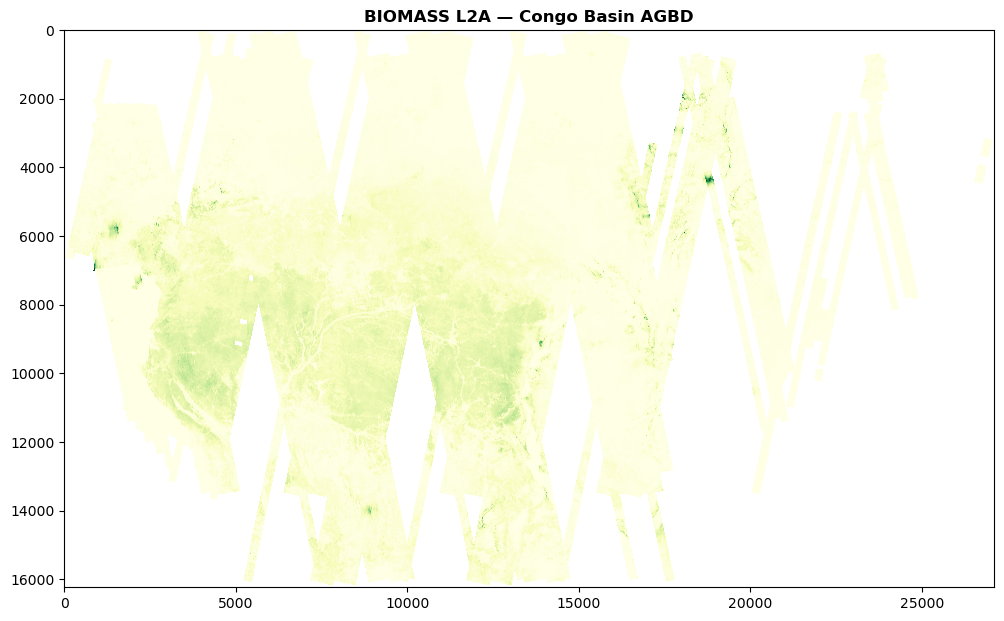

In [3]:
from pathlib import Path
import rasterio
import matplotlib.pyplot as plt
from rasterio.plot import show

tif_path = Path("../../../Examples_and_Data/Workshops/BIOMASS-Coding2026/Biomass_AGBD_Congo_Basin/agbd_map_L2Afullextent_congo_basin.tif")

with rasterio.open(tif_path) as src:
    print(f"CRS: {src.crs}, Size: {src.width}x{src.height}, Res: {src.res}")
    agbd = src.read(1, masked=True)

plt.figure(figsize=(12, 8))
show(agbd, cmap="YlGn", title="BIOMASS L2A — Congo Basin AGBD")
plt.show()


## 5. Extract AGBD per Plot (weighted)

In [4]:
from pathlib import Path
import numpy as np, pandas as pd, geopandas as gpd, rasterio
from rasterio.mask import mask as rio_mask
from rasterio.features import rasterize
from rasterio.transform import from_bounds

src_path = Path("../../../Examples_and_Data/Workshops/BIOMASS-Coding2026/Biomass_AGBD_Congo_Basin/agbd_map_L2Afullextent_congo_basin.tif")
gpkg_path = Path("Mondah_Plot_1ha.gpkg")
OVERSAMPLE = 10

def fractional_weights(geom, shape, tf):
    h, w = shape
    fh, fw = h * OVERSAMPLE, w * OVERSAMPLE
    bounds = rasterio.transform.array_bounds(h, w, tf)
    ftf = from_bounds(*bounds, fw, fh)
    fm = rasterize([geom.__geo_interface__], out_shape=(fh, fw), transform=ftf, fill=0, default_value=1, dtype=np.uint8)
    return fm.reshape(h, OVERSAMPLE, w, OVERSAMPLE).mean(axis=(1, 3))

def weighted_stats(data, weights, nodata=None):
    valid = np.isfinite(data) & (weights > 0)
    if nodata is not None and np.isfinite(nodata): valid &= data != nodata
    if not valid.any(): return {"n_pixels": 0, "weighted_mean": np.nan}
    d, w = data[valid], weights[valid]
    return {"n_pixels": int(d.size), "weighted_mean": float(np.average(d, weights=w)),
            "simple_mean": float(d.mean()), "min": float(d.min()), "max": float(d.max())}

plots = gpd.read_file(gpkg_path)
with rasterio.open(src_path) as src:
    pa = plots.to_crs(src.crs) if plots.crs != src.crs else plots.copy()
    results = []
    for idx, row in pa.iterrows():
        geom = row.geometry
        pid = row.get("name", row.get("id", idx))
        try:
            clipped, ctf = rio_mask(src, [geom.__geo_interface__], crop=True, all_touched=True, nodata=src.nodata, filled=True)
        except: continue
        wt = fractional_weights(geom, clipped[0].shape, ctf)
        st = weighted_stats(clipped[0], wt, src.nodata)
        st["plot_id"] = pid
        results.append(st)
        print(f"  {pid}: weighted_mean={st['weighted_mean']:.2f} t/ha")
    pd.DataFrame(results).to_csv("plot_agbd_results.csv", index=False)
    print("✓ Saved")


  0: weighted_mean=9.37 t/ha
  1: weighted_mean=9.19 t/ha
  2: weighted_mean=9.49 t/ha
  3: weighted_mean=10.40 t/ha
  4: weighted_mean=9.75 t/ha
  5: weighted_mean=9.43 t/ha
  6: weighted_mean=9.26 t/ha
  7: weighted_mean=11.26 t/ha
  8: weighted_mean=80.37 t/ha
  9: weighted_mean=12.27 t/ha
  10: weighted_mean=11.85 t/ha
  11: weighted_mean=14.69 t/ha
  12: weighted_mean=12.62 t/ha
  13: weighted_mean=10.65 t/ha
  14: weighted_mean=9.08 t/ha
✓ Saved


## 6. Update Tree Heights from CHMv2

In [5]:
from pathlib import Path
import numpy as np, geopandas as gpd, rasterio
from rasterio.transform import rowcol

base = Path("../../../biomass-hackathon-2026/topics/06A-CARBON")
trees = gpd.read_file(base / "Mondah_Trees.gpkg")
chm_path = base / "Mondah_CHMv2_clipped.tif"
CROWN_RADIUS_M = 5.0

with rasterio.open(chm_path) as src:
    trees_r = trees.to_crs(src.crs) if trees.crs != src.crs else trees
    chm = src.read(1); tf = src.transform; nd = src.nodata
    rpx = max(1, int(np.ceil(CROWN_RADIUS_M / abs(src.res[0]))))
    heights = []
    for _, row in trees_r.iterrows():
        try:
            r, c = rowcol(tf, row.geometry.x, row.geometry.y)
            w = chm[max(0,r-rpx):min(chm.shape[0],r+rpx+1), max(0,c-rpx):min(chm.shape[1],c+rpx+1)].astype(float)
            vm = (w > 0) & (w != nd if nd else True)
            heights.append(float(w[vm].max()) if vm.any() else np.nan)
        except: heights.append(np.nan)

trees["h_t_updated"] = heights
print(f"Updated: {sum(1 for h in heights if not np.isnan(h))} / {len(trees)}")
trees.to_file(base / "Mondah_Trees_updated.gpkg", driver="GPKG")
print("✓ Saved")


Updated: 6607 / 6692
✓ Saved


## 7. Species Inventory

In [6]:
species_counts = trees["species"].value_counts()
print(f"Total unique species: {len(species_counts)}\n")
print(species_counts.to_string())


Total unique species: 174

species
Aucoumea klaineana             582
Anthocleista sp.               497
Psychotria sp.                 279
Anthostema aubryanum           244
Diospyros sp.                  241
Musanga cecropioides           210
Sorindeia sp.                  208
Dichostemma glaucescens        173
Pycnanthus angolensis          161
Pausinystalia johimbe          152
Cleistopholis sp.              142
Coelocaryon sp.                141
Harungana madagascariensis     123
Xylopia sp.                    122
Macaranga sp.                  104
Alchornea cordifolia           103
Drypetes sp.                   101
Maprounea membranacea           90
Garcinia sp.                    81
Dichaetanthera sp.              79
Scyphocephalium mannii          77
Dacryodes sp.                   75
Dialium bipindense              72
Baphia buettneri                59
Staudtia kamerunensis           58
Xylopia aethiopica              55
Homalium sp.                    50
Carapa sp.          

## 8. Allometric Models — Single Species Plot

In [7]:
# Run allometric_height_to_dbh.py for per-species visualization
# %run allometric_height_to_dbh.py


## 9. Allometric Models — All Species + Predict DBH

In [8]:
# Run allometric_all_species.py
# Fits Weibull/Gompertz/Linear/Logistic/Hyperbola per species (>=30 samples)
# Global hyperbola fallback for species with <30 samples
# Adds: allom_model, dbh_updated columns
#
# %run allometric_all_species.py


## 10. Compute Updated AGB — Chave 2014

`AGB (kg) = 0.0673 × (wsg × D_cm² × H)^0.976`

In [9]:
import geopandas as gpd, numpy as np

base = "../../../biomass-hackathon-2026/topics/06A-CARBON"
trees = gpd.read_file(f"{base}/Mondah_Trees_updated.gpkg")

valid = (trees["dbh_updated"].notna() & (trees["dbh_updated"] > 0) &
         trees["h_t_updated"].notna() & (trees["h_t_updated"] > 0) &
         trees["wsg"].notna() & (trees["wsg"] > 0))

d_cm = trees.loc[valid, "dbh_updated"] * 100
trees["agb_updated"] = np.nan
trees.loc[valid, "agb_updated"] = 0.0673 * (trees.loc[valid, "wsg"] * d_cm**2 * trees.loc[valid, "h_t_updated"]) ** 0.976

c = trees["agb_updated"].notna()
print(f"agb_updated: {c.sum()}/{len(trees)}, range: {trees.loc[c,'agb_updated'].min():.1f}–{trees.loc[c,'agb_updated'].max():.1f} kg")
trees.to_file(f"{base}/Mondah_Trees_updated.gpkg", driver="GPKG")
print("✓ Saved")


KeyError: 'dbh_updated'

## 11. Plot-Level AGBD — Field vs Satellite

In [ ]:
import geopandas as gpd, numpy as np, rasterio
from rasterio.mask import mask as rio_mask

base = "../../../biomass-hackathon-2026/topics/06A-CARBON"
trees = gpd.read_file(f"{base}/Mondah_Trees_updated.gpkg")
plots = gpd.read_file(f"{base}/Mondah_Plot_1ha.gpkg")
sat_path = f"{base}/agbd_map_L2Afullextent_congo_basin.tif"

plots["area_ha"] = plots.geometry.area / 10000 if plots.crs.is_projected else plots.to_crs(plots.estimate_utm_crs()).geometry.area / 10000

print(f"{'Plot':>10} {'Area(ha)':>8} {'Field(t/ha)':>12} {'Satellite(t/ha)':>16}")
print("-" * 50)

with rasterio.open(sat_path) as src:
    plots_src = plots.to_crs(src.crs)
    for idx, row in plots.iterrows():
        pn = row.get("name", row.get("plot", idx))
        ah = row["area_ha"]
        field = trees.loc[trees["plot"] == pn].loc[trees["m_agb"] > 0, "m_agb"].sum() / 1000 / ah
        try:
            cl, _ = rio_mask(src, [plots_src.iloc[idx].geometry.__geo_interface__], crop=True, all_touched=True, filled=True)
            v = cl[0][(cl[0] != src.nodata) & np.isfinite(cl[0]) & (cl[0] > 0)]
            sat = v.mean() if v.size else np.nan
        except: sat = np.nan
        print(f"{pn:>10} {ah:8.2f} {field:12.1f} {sat:16.1f}")


## 12. (Bonus) TLS Tree Data from .mat Files

In [ ]:
import scipy.io as sio, numpy as np, pandas as pd, os, glob

mat_folder = os.path.expanduser("~/Examples_and_Data/Workshops/BIOMASS-Coding2026/TLS/Lope/OKO-03-mat/")
records = []
for fp in sorted(glob.glob(os.path.join(mat_folder, "*.mat"))):
    fn = os.path.basename(fp).replace(".mat", "")
    parts = fn.split("_")
    try:
        td = sio.loadmat(fp)["treedata"][0, 0]
        loc = td["location"].flatten()
        records.append({"filename": fn, "subplot": parts[0],
            "tree": parts[1] if len(parts) > 1 else "",
            "TotalVolume_m3": td["TotalVolume"].flatten()[0],
            "TreeHeight_m": td["TreeHeight"].flatten()[0],
            "DBHqsm_m": td["DBHqsm"].flatten()[0]})
    except Exception as e: print(f"ERROR {fn}: {e}")

df = pd.DataFrame(records)
df["DBH_cm"] = df["DBHqsm_m"] * 100
print(f"Trees: {len(df)}, DBH: {df['DBH_cm'].min():.1f}–{df['DBH_cm'].max():.1f} cm")
df.to_csv("OKO-03_tree_inventory.csv", index=False)
